# Example of the aitlas toolbox in the context of multi label image classification

In the TalloS dataset all Sentinel-2 have a corresponding DEM image. Only 5879 Sentinel-2 images have a corresponding Sentinel-1 image, but those images were not labeled. For that reason this notebook does not consider Sentinel-1 images.

## Import the required packages

In [ ]:
from aitlas.datasets import TalloSDataset
from aitlas.models import ResNet50MultiLabel
from aitlas.transforms import ResizeCenterCropFlipHVToTensor, ResizeCenterCropToTensor
from aitlas.utils import image_loader
import numpy as np

## Load the dataset and show images

Both Sentinel-2 and DEM images

43797


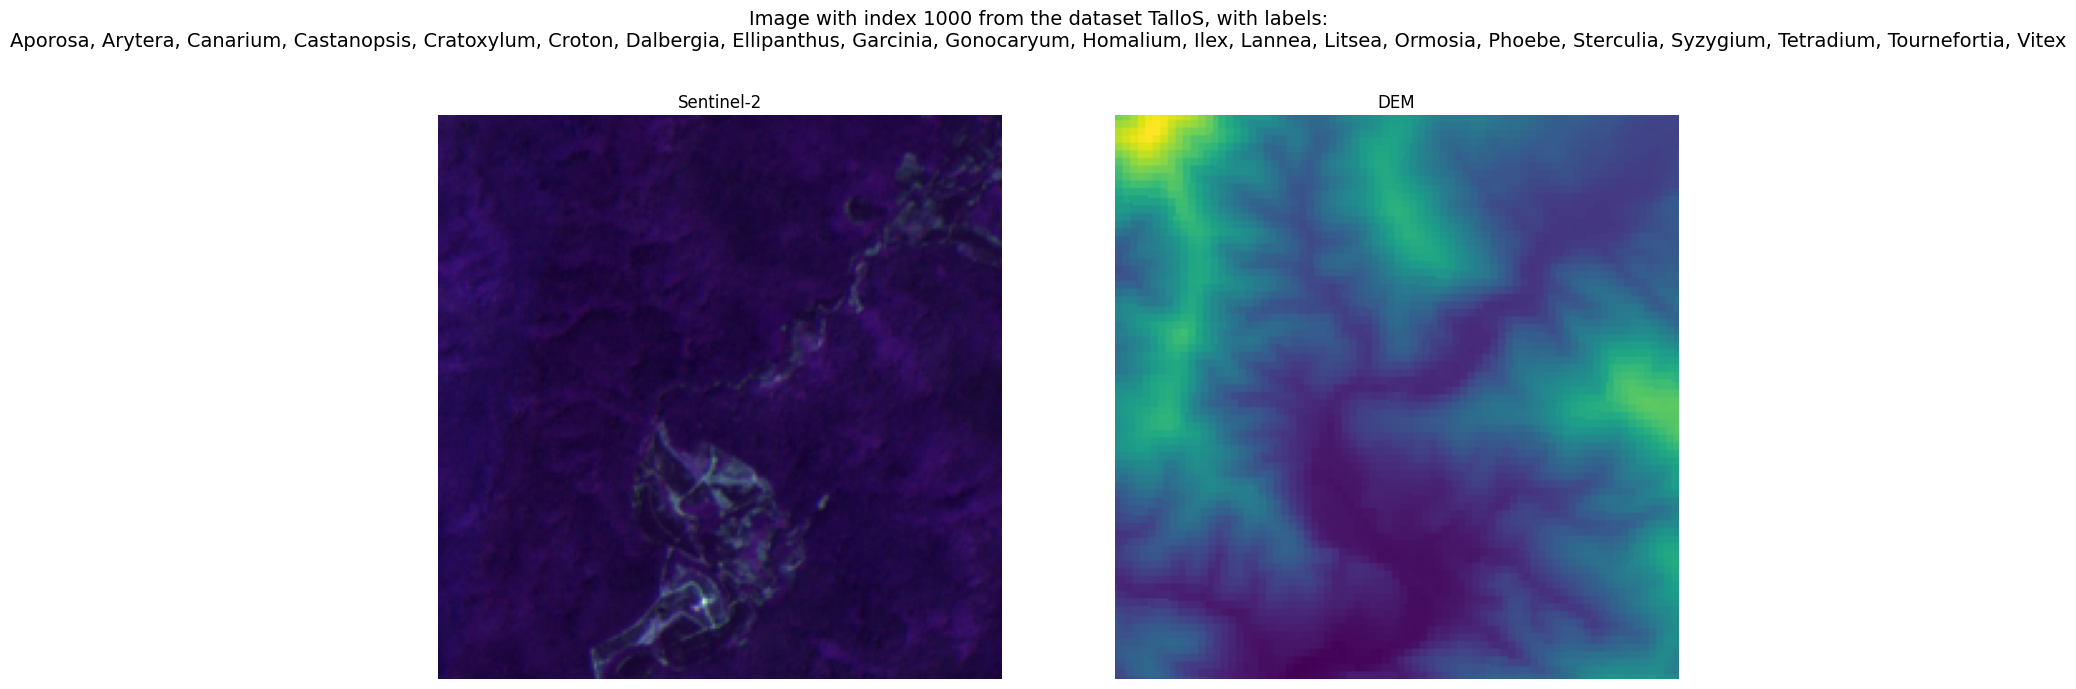

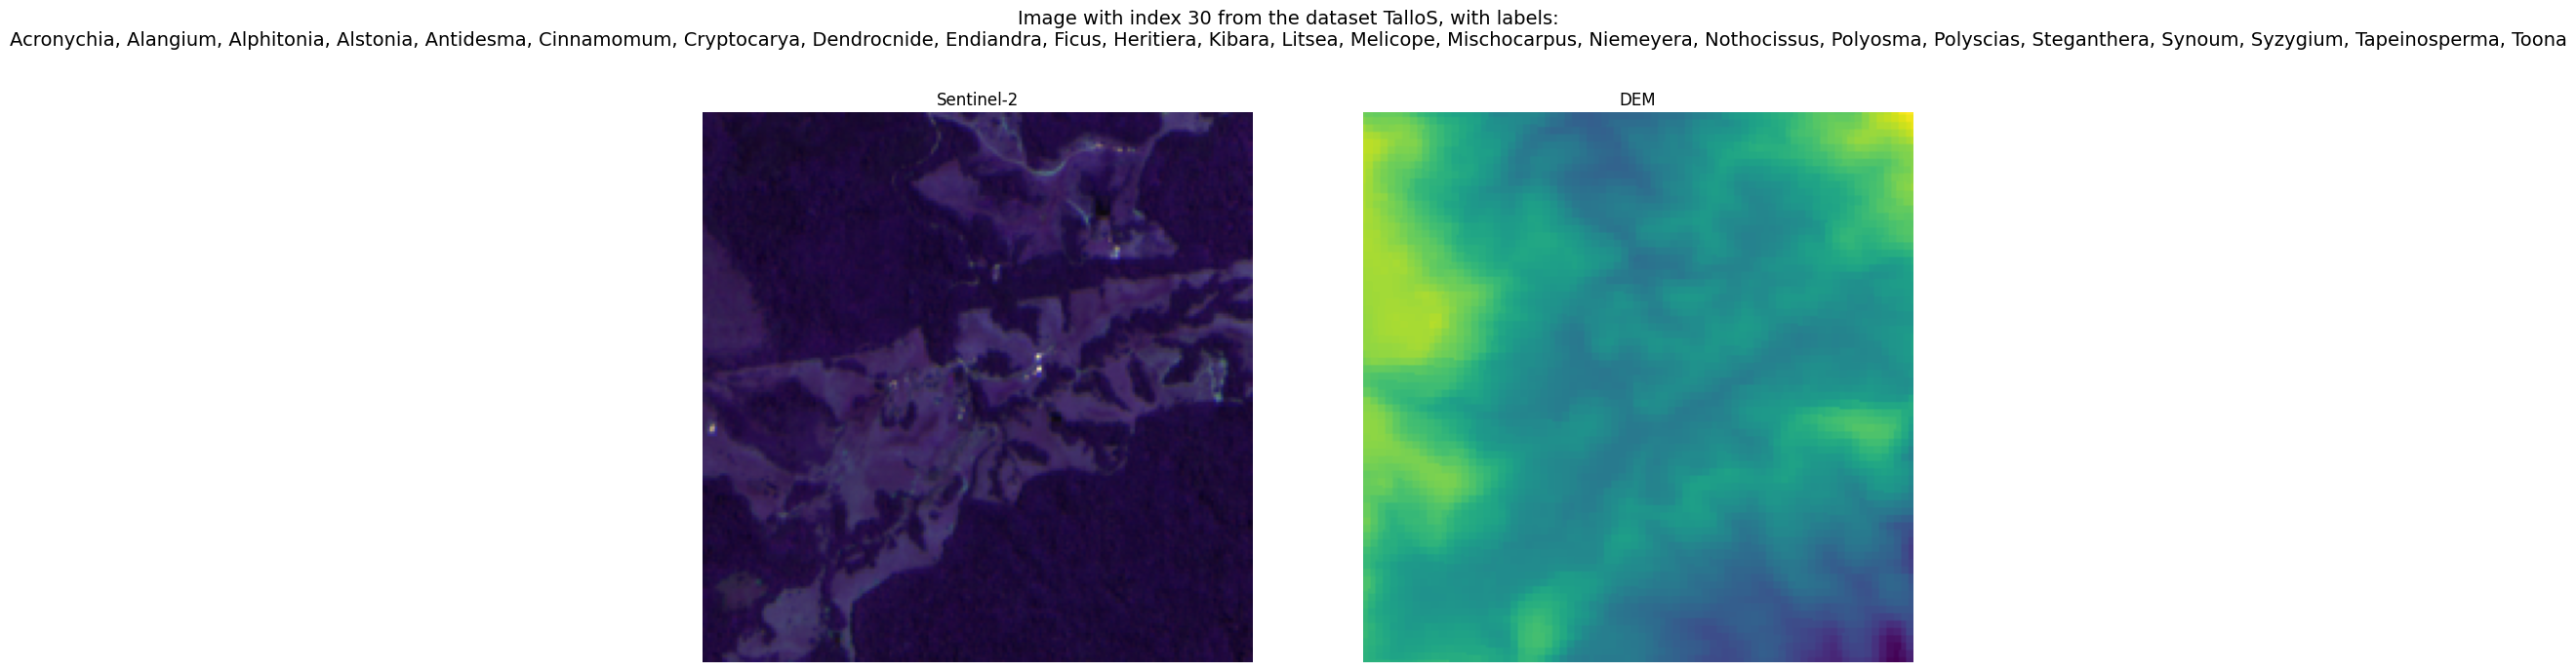

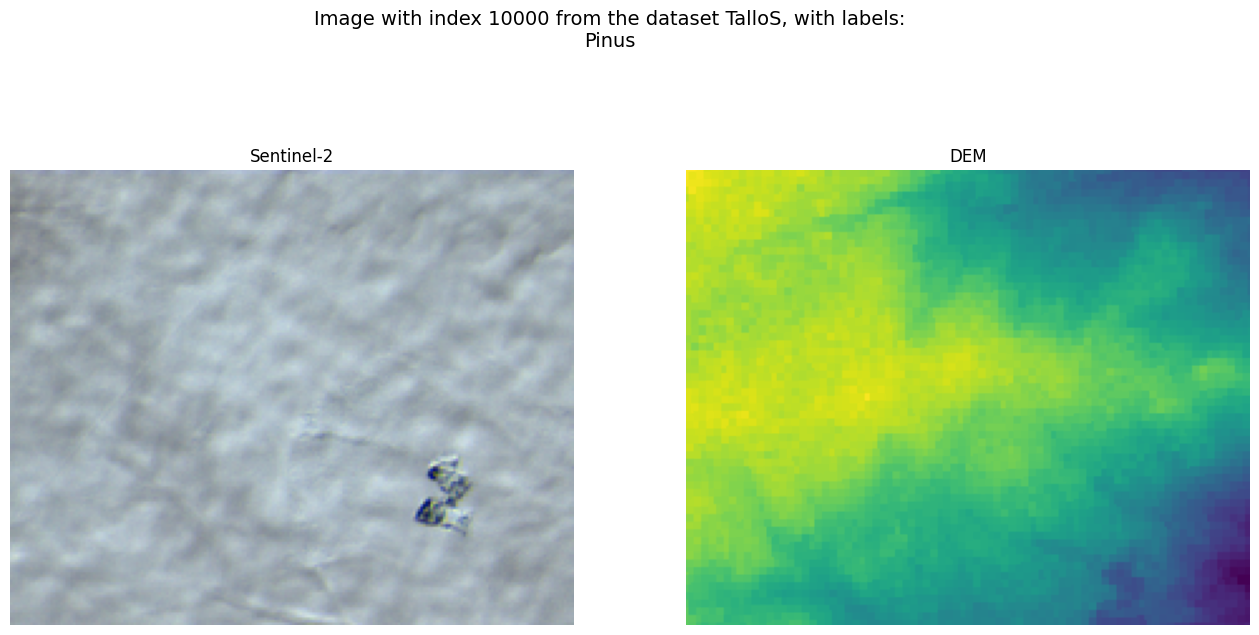

In [ ]:
# new 60/20/20 split
dataset_config = {
    "data_dir": "./data/tallos/TalloS_S2_DEM/",
    "annotations": "./data/tallos/annotations.csv",
    "csv_file": "./data/tallos/new_splits/tallos_train.csv",
    "imagery": "all",
    "selection": "rgb"
}
dataset = TalloSDataset(dataset_config)

print(len(dataset))

fig1 = dataset.show_image(1000)
fig2 = dataset.show_image(30)
fig3 = dataset.show_image(10000);

DEM images

61170


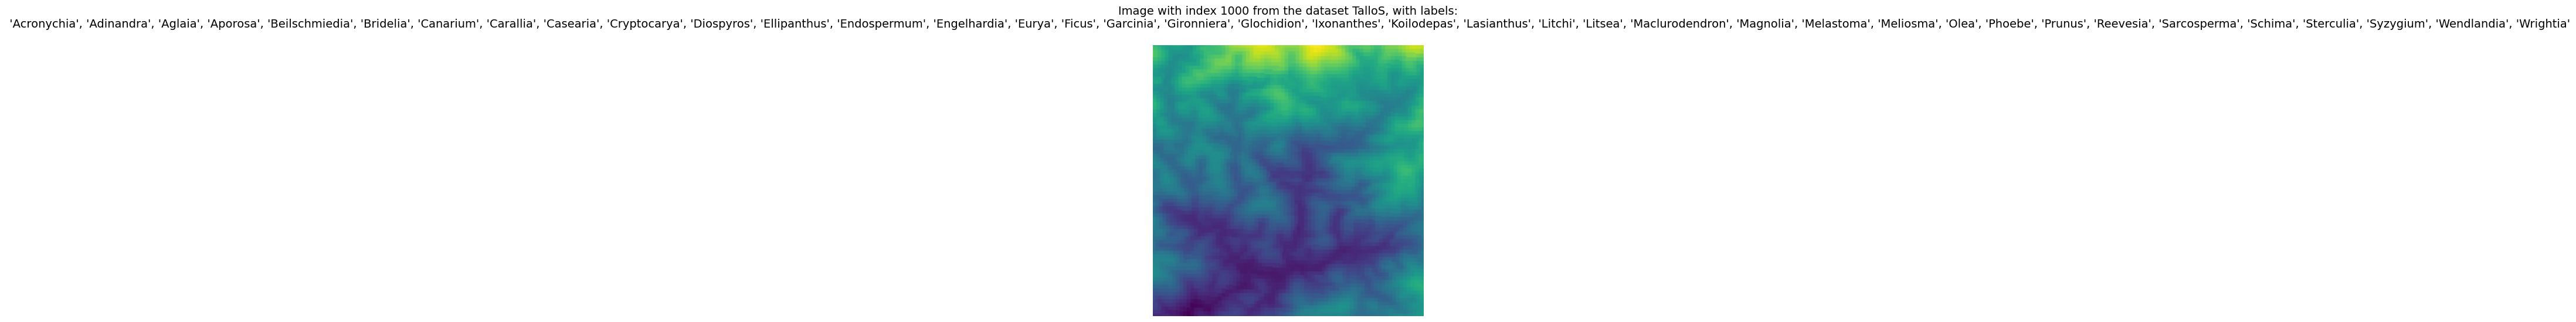

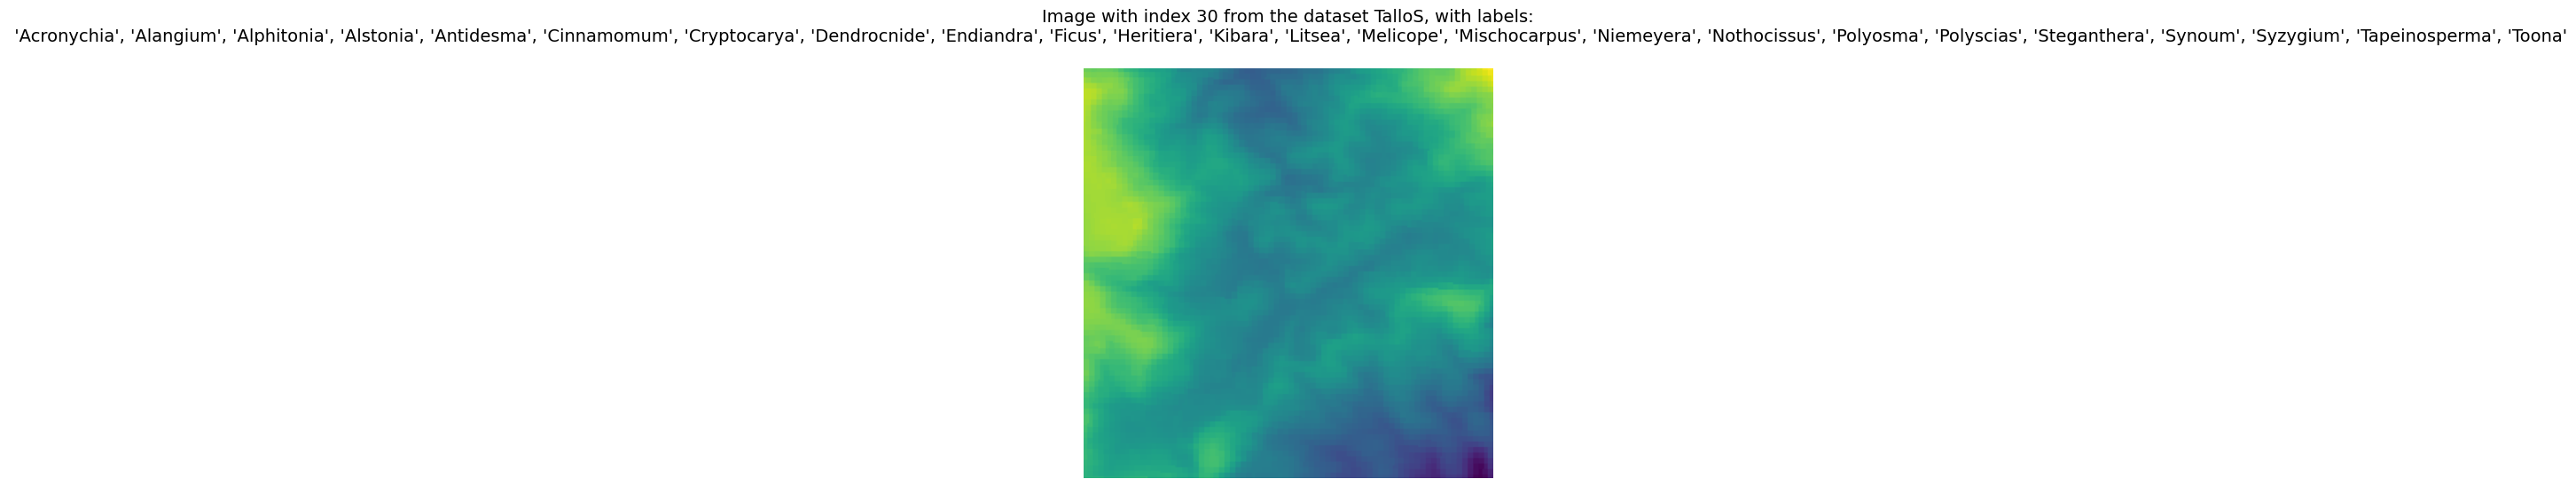

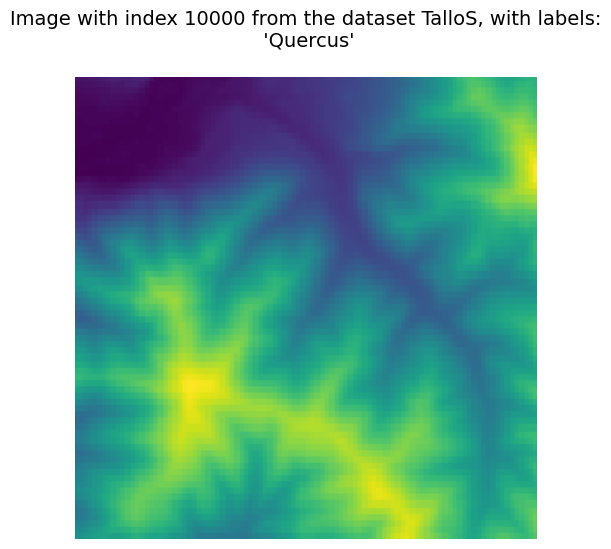

In [ ]:
# original splits
dataset_config = {
    "data_dir": "./data/tallos/TalloS_S2_DEM/",
    "annotations": "./data/tallos/annotations.csv",
    "csv_file": "./data/tallos/splits/train_samples.json",
    "task": "train",
    "imagery": "dem"
}
dataset = TalloSDataset(dataset_config)

print(len(dataset))

fig1 = dataset.show_image(1000)
fig2 = dataset.show_image(30)
fig3 = dataset.show_image(10000);

S2 images

In [ ]:
# new 60/20/20 split and user-defined bands combination
dataset_config = {
    "data_dir": "./data/tallos/TalloS_S2_DEM/",
    "annotations": "./data/tallos/annotations.csv",
    "csv_file": "./data/tallos/new_splits/tallos_train.csv",
    "imagery": "sentinel2",
    "selection": "bands",
    "bands_s2": ["B02","B03","B04","B05","B06"]
}
dataset = TalloSDataset(dataset_config)

print(len(dataset))

43797


61170


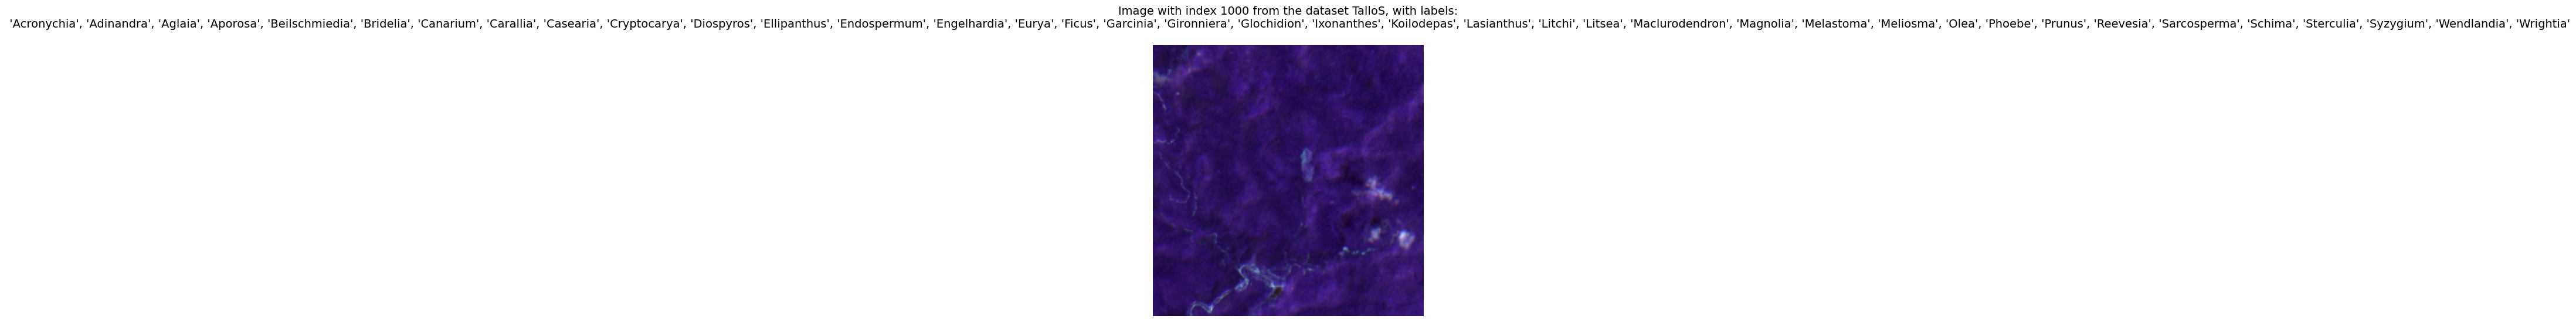

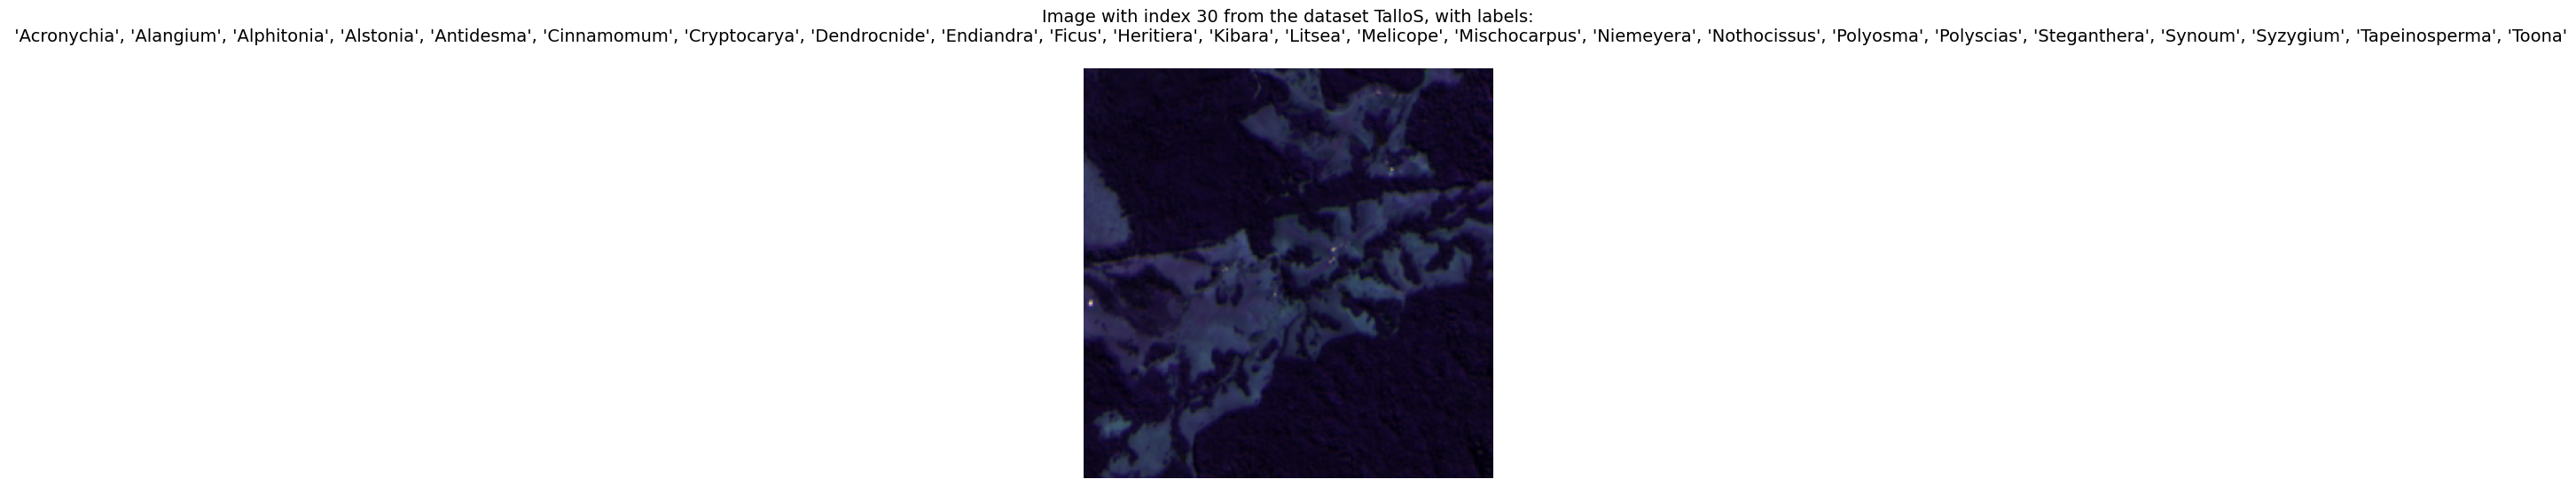

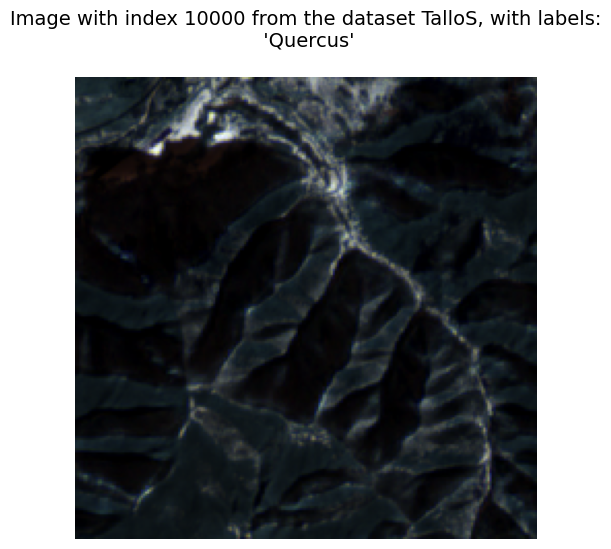

In [ ]:
# original train/val/test split and rgb images
dataset_config = {
    "data_dir": "./data/tallos/TalloS_S2_DEM/",
    "annotations": "./data/tallos/annotations.csv",
    "csv_file": "./data/tallos/splits/train_samples.json",
    "task": "train",
    "imagery": "sentinel2",
    "selection": "rgb"
}
dataset = TalloSDataset(dataset_config)

print(len(dataset))

fig1 = dataset.show_image(1000)
fig2 = dataset.show_image(30)
fig3 = dataset.show_image(10000);

2026-03-26 09:51:08,830 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
2026-03-26 09:51:08,843 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


2026-03-26 09:51:08,858 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
2026-03-26 09:51:08,873 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
2026-03-26 09:51:08,887 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
2026-03-26 09:51:08,901 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
2026-03-26 09:51:08,915 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
2026-03-26 09:51:08,927 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


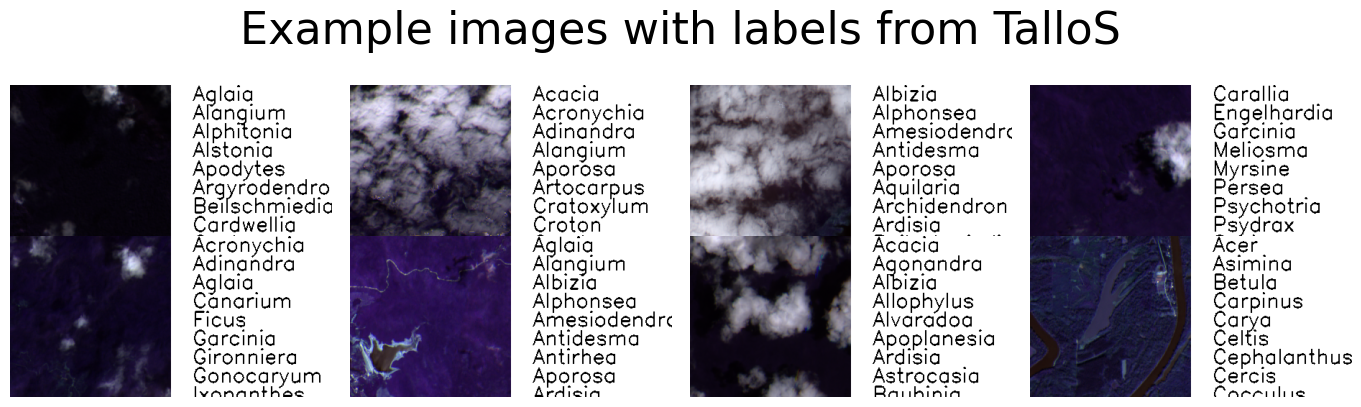

In [20]:
fig4 = dataset.show_batch(8)

## Inspect the data

In [21]:
dataset.data_distribution_table()

,Label,Count
0,Abarema,1
1,Abelmoschus,28
2,Abies,13407
3,Abrophyllum,258
4,Abuta,1
...,...,...
1359,Ziziphus,6112
1360,Zollernia,2
1361,Zuelania,10466
1362,Zygia,5917


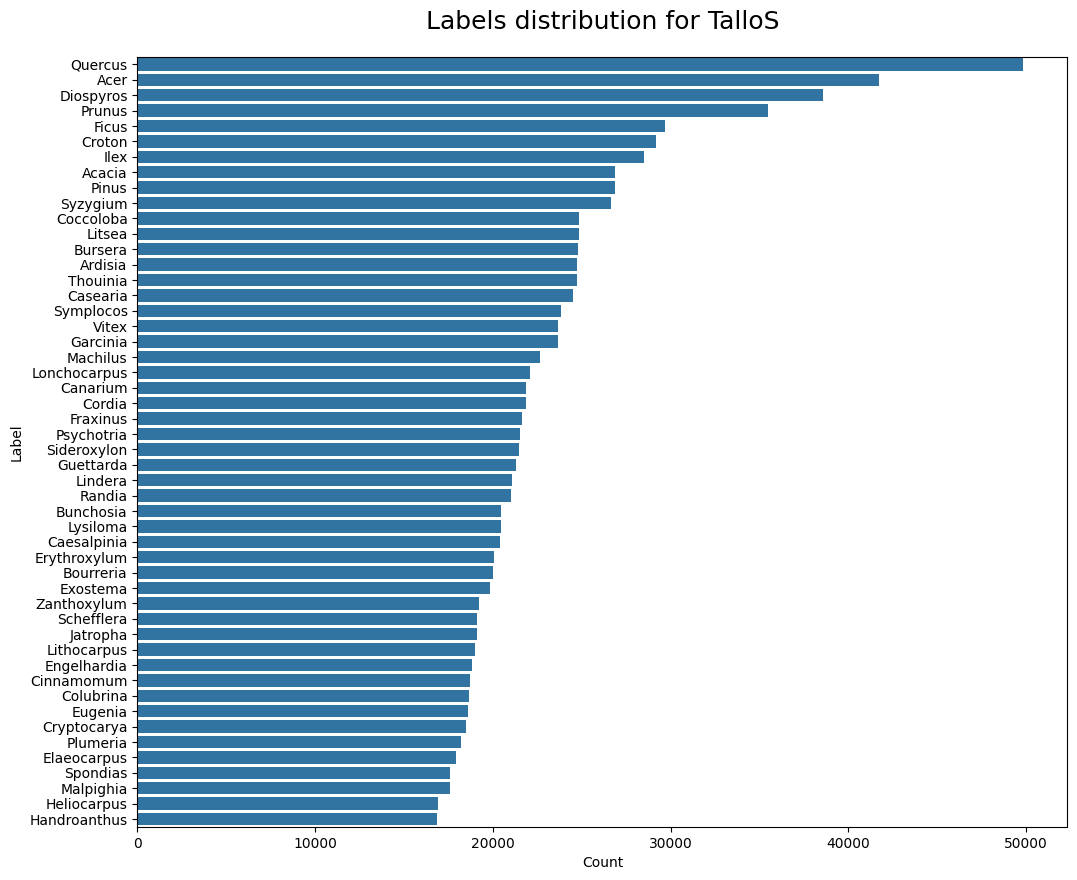

In [17]:
fig = dataset.data_distribution_barchart() # displays the 50 majority classes

## Load train and test splits

New 60/20/20 split

In [ ]:
train_dataset_config = {
    "batch_size": 32,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/tallos/TalloS_S2_DEM/",
    "annotations": "./data/tallos/annotations.csv",
    "csv_file": "./data/tallos/new_splits/tallos_train.csv",
    "imagery": "sentinel2",
    "selection": "rgb",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

train_dataset = TalloSDataset(train_dataset_config)
train_dataset.transform = ResizeCenterCropFlipHVToTensor() 

test_dataset_config = {
    "batch_size": 16,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/tallos/TalloS_S2_DEM/",
    "annotations": "./data/tallos/annotations.csv",
    "csv_file": "./data/tallos/new_splits/tallos_val.csv",
    "imagery": "sentinel2",
    "selection": "rgb",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

test_dataset = TalloSDataset(test_dataset_config)
len(train_dataset), len(test_dataset)

(43797, 14565)

## Setup and create the model for training

In [ ]:
epochs = 1
model_directory = "./data/experiments/tallos/"
model_config = {
    "num_classes": 1364, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5, 
    "metrics": ["accuracy", "precision", "recall", "f1_score"]
}
model = ResNet50MultiLabel(model_config)
model.prepare()

## Training and evaluation

In [9]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    val_dataset=test_dataset,
    run_id='1',
)

2026-03-11 10:35:31,343 INFO Starting training.
training: 100%|██████████| 1369/1369 [02:14<00:00, 10.20it/s]
2026-03-11 10:37:45,890 INFO epoch: 1, time: 134, loss:  0.09090
testing on train set: 100%|██████████| 1369/1369 [01:04<00:00, 21.19it/s]
2026-03-11 10:38:51,387 INFO Accuracy:0.9881801382102994, Accuracy per Class:[0.99995433 0.99956618 0.93193598 ... 0.97650524 0.98785305 0.99680343], Precision Micro:0.7752375328852611, Precision Macro:0.16593927337441375, Precision Weighted:0.6503503413936262, Precision per Class:[0.         0.         0.8436214  ... 0.80954665 0.83151261 0.        ], Recall Micro:0.5559350857628743, Recall Macro:0.12977265129568577, Recall Weighted:0.5559350857628743, Recall per Class:[0.         0.         0.30881245 ... 0.93490305 0.93791469 0.        ], F1_score Micro:0.6475219491351127, F1_score Macro:0.13726207867899154, F1_score Weighted:0.5777463797218612, F1_score per Class:[0.         0.         0.45212277 ... 0.86772079 0.88151448 0.        ]
tes

0.09090445248385981

## Predictions

2026-03-11 11:33:59,636 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/tallos/checkpoint.pth.tar
2026-03-11 11:34:00,663 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/tallos/checkpoint.pth.tar at epoch 2


14466


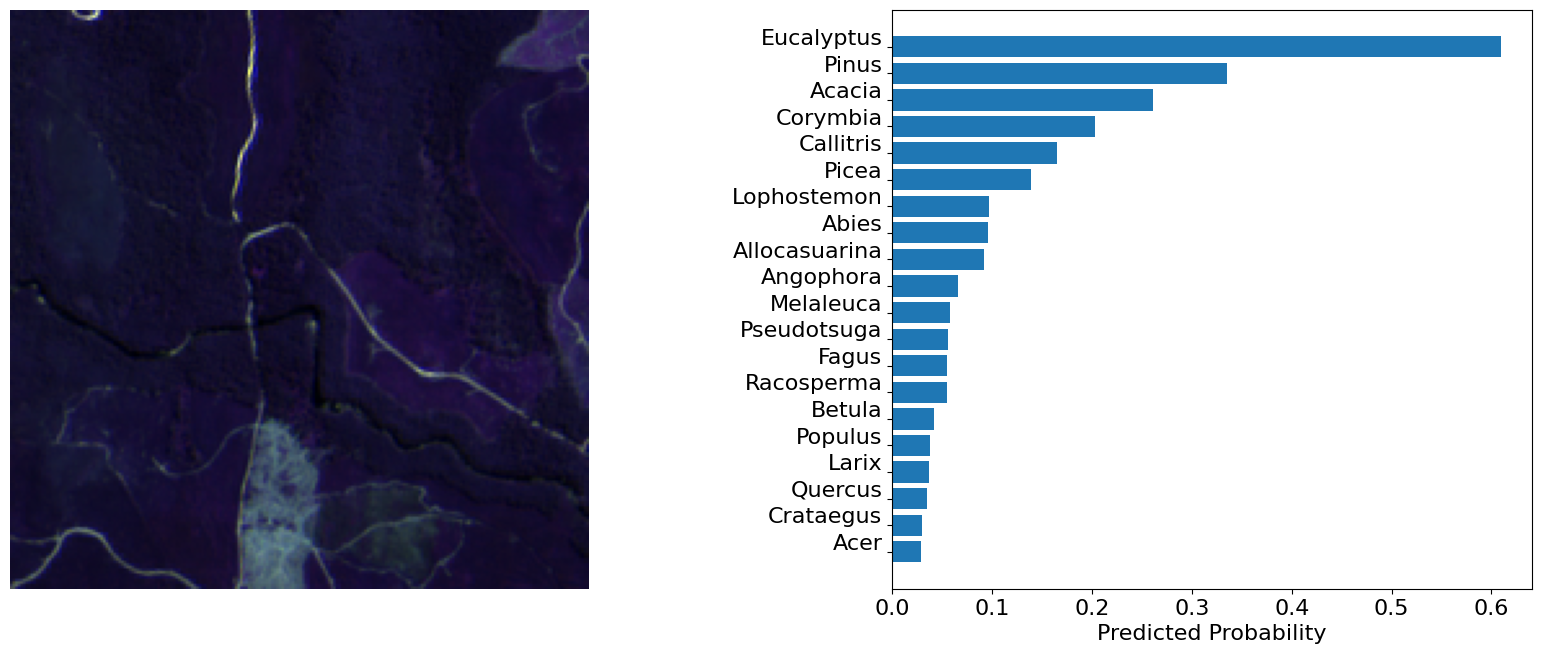

In [ ]:
model_path = "./data/experiments/tallos/checkpoint.pth.tar"

labels = []
with open("./data/tallos/labels_list.csv", "r") as f:
    for label in f:
        labels.append(label)

transform = ResizeCenterCropToTensor()
model.load_model(model_path)

test_dataset_config = {
    "data_dir": "./data/tallos/TalloS_S2_DEM/",
    "annotations": "./data/tallos/annotations.csv",
    "csv_file": "./data/tallos/new_splits/tallos_test.csv",
    "imagery": "sentinel2",
    "selection": "rgb"
}

test_dataset = TalloSDataset(test_dataset_config)
print(len(test_dataset))

image = test_dataset[100][0]
fig = model.predict_image(image, labels, transform)
# the amount of classes is too high for display
# keep only the 20 classes with the highest probability
ax = fig.axes[1]
# get bars and their probability values
bars = ax.patches
probs = [bar.get_width() for bar in bars]

top_k = 20
top_idx = np.argsort(probs)[-top_k:][::-1]

# extract corresponding labels
yticks = [tick.get_text() for tick in ax.get_yticklabels()]
top_labels = [yticks[i] for i in top_idx]
top_probs = [probs[i] for i in top_idx]

ax.clear()
ax.barh(top_labels, top_probs)
ax.set_xlabel("Predicted Probability")
ax.invert_yaxis()
fig.canvas.draw()